# Week 2: Feature Engineering Report
**Iran the Numbers** | Iranian Churn | Can engineered usage features compensate for missing warning flags?

Primary metric: average precision (AP), 5-fold StratifiedKFold on the training split.
Every step is compared with the baseline, and all scores are collected in the results log (section 10).

---
<h2 style="text-align:center; color:blue;">Part 1: Data Preparation</h2>

---

## 0. Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn import set_config
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, FunctionTransformer, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV, SelectFromModel
from sklearn.manifold import TSNE

# Keep column names after every pipeline step (needed to see which features are selected)
set_config(transform_output='pandas')

# Hide scikit-learn deprecation warnings (e.g. penalty='l1' is deprecated in the newest versions but still gives an L1 penalty;
# this is checked with an assert in section 9)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Inconsistent values')

RANDOM_STATE = 42
TARGET = 'churn'
print(f"sklearn version: {sklearn.__version__}")

sklearn version: 1.9.0


## 1. Load data

In [2]:
# 1) Load the Iranian Churn dataset (UCI id=563): local CSV copy if present, otherwise download it from UCI
if os.path.exists('Customer_Churn.csv'):
    df = pd.read_csv('Customer_Churn.csv')
else:
    from ucimlrepo import fetch_ucirepo      # pip install ucimlrepo
    df = fetch_ucirepo(id=563).data.original

In [3]:
# 2) Normalise column names: 'Call  Failure' (double space) becomes 'call_failure'
df.columns = df.columns.str.strip().str.lower().str.replace(r'\s+', '_', regex=True)
df.columns

Index(['call_failure', 'complains', 'subscription_length', 'charge_amount',
       'seconds_of_use', 'frequency_of_use', 'frequency_of_sms',
       'distinct_called_numbers', 'age_group', 'tariff_plan', 'status', 'age',
       'customer_value', 'churn'],
      dtype='str')

In [4]:
# 3) Shape, dtypes, missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   call_failure             3150 non-null   int64  
 1   complains                3150 non-null   int64  
 2   subscription_length      3150 non-null   int64  
 3   charge_amount            3150 non-null   int64  
 4   seconds_of_use           3150 non-null   int64  
 5   frequency_of_use         3150 non-null   int64  
 6   frequency_of_sms         3150 non-null   int64  
 7   distinct_called_numbers  3150 non-null   int64  
 8   age_group                3150 non-null   int64  
 9   tariff_plan              3150 non-null   int64  
 10  status                   3150 non-null   int64  
 11  age                      3150 non-null   int64  
 12  customer_value           3150 non-null   float64
 13  churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [5]:
# 4) Class balance
df[TARGET].value_counts(normalize=True).round(3)

churn
0    0.843
1    0.157
Name: proportion, dtype: float64

### 1.1 Feature summary table
Decision and justification for every original feature, based on the results of the sections below.
All statistics in the table are computed on the training split (2280 rows).

| Original feature | Decision (keep / transform / encode / remove) | Justification |
|---|---|---|
| `call_failure` | transform: log1p + numerator of `failure_rate` | Raw count alone is uninformative (r = 0.00 with churn; churn rate flat at 14-18% across quartiles); failures only matter relative to how much the customer calls. |
| `complains` | keep in set A, **remove** in B/C (by design) | Near-label flag: 81.3% churn when 1 vs 10.0% when 0. Recorded only after dissatisfaction is explicit, so the RQ tests the model without it. Already 0/1, so no encoding. |
| `subscription_length` | keep as-is | The only left-skewed feature (skew -1.28), so log1p doesn't apply. Relation to churn is non-monotonic (12%, 21%, 18%, 11% by quartile), which trees capture and LR can't. |
| `charge_amount` | transform: log1p, kept as one ordinal column (no one-hot) | Skew 2.55 with 56% zeros. Monotonic link to churn (24% churn at 0, 0% at 4 and above), which a single ordinal column preserves. Levels 5-10 have only 5-23 customers each, so one-hot would create sparse columns. |
| `seconds_of_use` | transform: log1p, then **removed by L1** (section 9) | r = 0.946 with `frequency_of_use`; dropping it alone costs a small but consistent 0.004 AP (0.754 to 0.750, lower in all 5 folds), so it is kept until feature selection; L1 removes it once `avg_call_duration` carries its information. |
| `frequency_of_use` | transform: log1p + denominator of all three ratios | Main measure of activity (r = -0.30 with churn, the strongest behavioural signal). Dropping it costs about one std of AP (0.730), so it is kept. |
| `frequency_of_sms` | transform: log1p + `sms_share` | Skew 1.98, 18% zeros. Kept over `customer_value` (r = 0.921): directly interpretable, same AP. |
| `distinct_called_numbers` | transform: log1p, then **removed by L1** (section 9) | Skew 1.04; r = 0.735 with `frequency_of_use` - below 0.90, but L1 finds it redundant with activity counts. |
| `age_group` | keep (ordinal 1-5) | Exact 1:1 mapping to `age` (each group has a single age: 15/25/30/45/55), so only one of the two is needed. Near-zero link to churn (r = -0.01). |
| `tariff_plan` | encode (1/2 to 0/1) and keep | 92% of customers are on plan 1, so it is checked in the variance analysis, but not removed: churn is 2.2% on plan 2 vs 16.8% on plan 1. |
| `status` | keep in set A, **remove** in B/C (by design); encode (1/2 to 0/1) | Inactive customers churn at 47.4% vs 5.7%. Inactivity is a late symptom of leaving rather than an early signal, so it is excluded together with `complains`. |
| `age` | **remove** | Same information as `age_group` (r = 0.962, 1:1 mapping); dropping it keeps AP at 0.754. |
| `customer_value` | **remove** | Opaque operator score, r = 0.921 with `frequency_of_sms`; dropping it keeps AP at 0.754, and the interpretable SMS count stays. |

---

## 2. Duplicate handling

In [6]:
# 1) Count exact duplicates
print(f"Duplicated rows: {df.duplicated().sum()}")

Duplicated rows: 300


In [7]:
# 2) Keep a copy with duplicates for the sensitivity check in section 4.1
df_with_dups = df.copy()

# 3) Remove duplicates BEFORE the split
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape before: {df_with_dups.shape}\nShape after: {df.shape}")
print(f"Churn rate after: {df[TARGET].mean():.3f}")

Shape before: (3150, 14)
Shape after: (2850, 14)
Churn rate after: 0.156


**Result:** 300 of 3150 rows (9.5%) are exact duplicates. We drop them before the split, otherwise the same row could end up in both train and test.
2850 rows remain and the churn rate barely changes (15.7% before, 15.6% after).

---

## 3. Train/test split

In [8]:
# 1) Features and target
X = df.drop(columns=TARGET)
y = df[TARGET]

# 2) Stratified 80/20 split: the churn share (~16%) is the same in both parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train size: {X_train.shape}\nTest size: {X_test.shape}")

Train size: (2280, 13)
Test size: (570, 13)


`X_test` is not used for any score in this notebook. It is only used in the last cell to check that the final pipeline works on new data.

---
<h2 style="text-align:center; color:blue;">Part 2: Baseline and Feature Analysis</h2>

---

## 4. Baseline

In [9]:
# 1) The same 5 folds for every step, so scores are comparable
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2) Results log: one row per step (step, number of features, AP on the 5 folds)
results = []

In [10]:
# 3) Baseline: all 13 features, scaler + logistic regression
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000)),
])

baseline_cv = cross_val_score(baseline, X_train, y_train, scoring='average_precision', cv=cv)
results.append(('baseline', 13, baseline_cv))
print(f"Baseline AP: {baseline_cv.round(4)}, mean = {baseline_cv.mean():.4f}, std = {baseline_cv.std():.4f}")

Baseline AP: [0.7903 0.7587 0.7517 0.7317 0.7372], mean = 0.7539, std = 0.0206


StandardScaler is part of the baseline. Without it, logistic regression treats features on very different scales
(0-17090 seconds vs 0/1 flags) unequally.

### 4.1 Duplicate sensitivity check (from the proposal)

In [11]:
# 1) Duplicated rows that match rows of the training split (the test split is not used)
train_rows = pd.concat([X_train, y_train], axis=1)
dups = df_with_dups.merge(train_rows, how='inner')
X_dups = dups.drop(columns=TARGET)
y_dups = dups[TARGET]
print(f"Train rows with duplicates: {len(dups)}")

Train rows with duplicates: 2532


In [12]:
# 2) Grouped CV: identical rows share one group, so all copies fall into the same fold
groups = dups.groupby(list(dups.columns)).ngroup()
grouped_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grouped_scores = cross_val_score(baseline, X_dups, y_dups, groups=groups, scoring='average_precision', cv=grouped_cv)

# 3) Plain CV: copies of one row can land in both the training and the validation fold
plain_scores = cross_val_score(baseline, X_dups, y_dups, scoring='average_precision', cv=cv)

print(f"Deduplicated:                mean = {baseline_cv.mean():.4f}, std = {baseline_cv.std():.4f}")
print(f"With duplicates, grouped CV: mean = {grouped_scores.mean():.4f}, std = {grouped_scores.std():.4f}")
print(f"With duplicates, plain CV:   mean = {plain_scores.mean():.4f}, std = {plain_scores.std():.4f}")

Deduplicated:                mean = 0.7539, std = 0.0206
With duplicates, grouped CV: mean = 0.7529, std = 0.0639
With duplicates, plain CV:   mean = 0.7554, std = 0.0365


**Evaluation:** keeping the duplicates does not change the score: 0.753 with grouped CV and 0.755 with plain CV, vs 0.754 without duplicates.
All differences are within noise (std 0.02-0.06), so the duplicates do not inflate the score here.
We still remove them before the split because it is the safe choice and costs nothing.
(The grouped CV score depends on how the sklearn version assigns groups to folds, so it can differ slightly between versions; the conclusion does not.)

---

## 5. Variance analysis

In [13]:
# 1) Variance and the share of the most frequent value for every feature (close to 1 means almost constant)
top_share = X_train.apply(lambda col: col.value_counts(normalize=True).iloc[0])
variance_table = pd.DataFrame({'variance': X_train.var(), 'most frequent value share': top_share})
# plain number format instead of scientific notation (7.2e-02)
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(variance_table.sort_values('most frequent value share', ascending=False))

,variance,most frequent value share
tariff_plan,0.072,0.922
complains,0.073,0.920
status,0.182,0.761
charge_amount,2.366,0.556
age_group,0.816,0.445
age,80.485,0.445
call_failure,54.530,0.220
frequency_of_sms,12784.834,0.183
subscription_length,78.134,0.077
seconds_of_use,18179445.522,0.040


Raw variance depends on the scale of the feature (seconds of use vs 0/1 flags), so it cannot be compared across features. The share of the most frequent value is the comparable measure of how close a feature is to constant.

In [14]:
# 2) Churn rate by value for the two most one-sided features
for col in ['complains', 'tariff_plan']:
    print(f"{col}: {y_train.groupby(X_train[col]).mean().round(3).to_dict()}")

complains: {0: 0.1, 1: 0.813}
tariff_plan: {1: 0.168, 2: 0.022}


**Evaluation:** no feature is constant. The two least varied features are `tariff_plan` and `complains`: about 92% of clients share one value, and their variance is the lowest in the table (0.072 and 0.073). Their churn rates differ a lot between values (2% on plan 2 vs 17% on plan 1; 81% with a complaint vs 10% without), so removing them would lose signal. **Nothing removed, AP unchanged** (same as baseline).

---

## 6. Correlation analysis (|r| > 0.90)

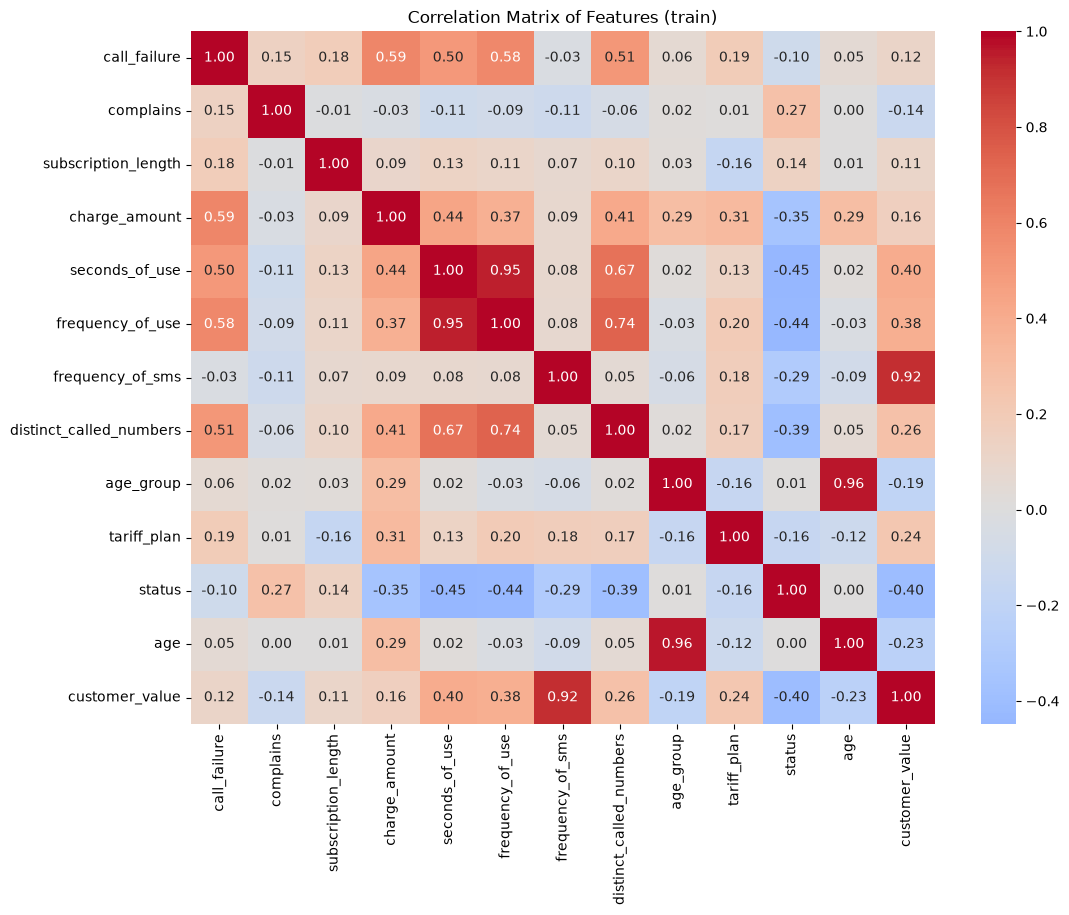

In [15]:
# 1) Correlation heatmap (train only)
corr_matrix = X_train.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Features (train)')
plt.show()

In [16]:
# 2) Pairs with |r| > 0.90 (upper triangle only, so each pair appears once)
upper = corr_matrix.abs().where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
pairs = upper.stack()
pairs[pairs > 0.9].round(3)

seconds_of_use    frequency_of_use    0.946
frequency_of_sms  customer_value      0.921
age_group         age                 0.962
dtype: float64

In [17]:
# 3) Drop one feature of each pair and compare AP with the baseline (0.754)
for col in ['age', 'seconds_of_use', 'frequency_of_use', 'customer_value', 'frequency_of_sms']:
    scores = cross_val_score(baseline, X_train.drop(columns=[col]), y_train, scoring='average_precision', cv=cv)
    results.append((f'drop {col}', 12, scores))
    print(f"drop {col}: mean = {scores.mean():.4f}, std = {scores.std():.4f}")

drop age: mean = 0.7543, std = 0.0202
drop seconds_of_use: mean = 0.7498, std = 0.0204
drop frequency_of_use: mean = 0.7300, std = 0.0291
drop customer_value: mean = 0.7542, std = 0.0201
drop frequency_of_sms: mean = 0.7546, std = 0.0177


**Evaluation:** three pairs above 0.90. CV std is ~0.02, so differences smaller than that are treated as noise.
- `age` / `age_group` (0.96): identical information (1:1 mapping), so drop `age`; AP stays at 0.754.
- `frequency_of_sms` / `customer_value` (0.92): dropping either leaves AP unchanged (0.754 / 0.755), so drop `customer_value`, an opaque operator score; `frequency_of_sms` is directly interpretable.
- `seconds_of_use` / `frequency_of_use` (0.95): dropping `frequency_of_use` costs about one std (from 0.754 to 0.730), so keep it. Dropping `seconds_of_use` costs 0.004 (0.750): small, but lower in all 5 folds (section 10). Keep it for now, combine the pair in `avg_call_duration` (section 7) and leave the final call to feature selection (section 9).

In [18]:
# 4) Decision: drop age and customer_value, 11 features remain for the next steps
X_train_clean = X_train.drop(columns=['age', 'customer_value'])
print(f"Train size after dropping: {X_train_clean.shape}")

# 5) AP on these 11 features: the reference point for the new features in section 7
clean_cv = cross_val_score(baseline, X_train_clean, y_train, scoring='average_precision', cv=cv)
results.append(('drop age + customer_value', 11, clean_cv))
print(f"11 features: mean = {clean_cv.mean():.4f}, std = {clean_cv.std():.4f}")

Train size after dropping: (2280, 11)
11 features: mean = 0.7541, std = 0.0206


---
<h2 style="text-align:center; color:blue;">Part 3: Feature Engineering</h2>

---

## 7. Engineered features

- `avg_call_duration = seconds_of_use / (frequency_of_use + 1)` - long vs short calls, independent of activity level
- `sms_share = frequency_of_sms / (frequency_of_sms + frequency_of_use + 1)` - how the customer communicates
- `failure_rate = call_failure / (frequency_of_use + 1)` - raw failures are uninformative (r ~0 with churn); failures per call are not

Implemented as a FunctionTransformer, so it lives inside the Pipeline.

In [19]:
# 1) Three ratio features (+1 in the denominator avoids division by zero)
def add_ratios(X):
    X = X.copy()
    X['avg_call_duration'] = X['seconds_of_use'] / (X['frequency_of_use'] + 1)
    X['sms_share'] = X['frequency_of_sms'] / (X['frequency_of_sms'] + X['frequency_of_use'] + 1)
    X['failure_rate'] = X['call_failure'] / (X['frequency_of_use'] + 1)
    return X


add_ratios(X_train_clean)[['avg_call_duration', 'sms_share', 'failure_rate']].describe().round(3)

,avg_call_duration,sms_share,failure_rate
count,2280.000,2280.000,2280.000
mean,60.066,0.355,0.133
std,29.337,0.292,0.151
min,0.000,0.000,0.000
25%,43.571,0.079,0.023
50%,58.033,0.318,0.096
75%,72.050,0.569,0.184
max,325.000,0.976,2.333


In [20]:
# 2) CV with the ratios inside the pipeline
ratios_pipe = Pipeline([
    ('ratios', FunctionTransformer(add_ratios)),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000)),
])

ratios_cv = cross_val_score(ratios_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)
results.append(('+ 3 ratios', 14, ratios_cv))
print(f"+ 3 ratios: mean = {ratios_cv.mean():.4f}, std = {ratios_cv.std():.4f}")

+ 3 ratios: mean = 0.7534, std = 0.0194


In [21]:
# 3) Each ratio separately: add one new feature and drop the other two
all_ratios = ['avg_call_duration', 'sms_share', 'failure_rate']

for ratio in all_ratios:
    other_ratios = [r for r in all_ratios if r != ratio]
    one_ratio_pipe = Pipeline([
        ('ratios', FunctionTransformer(add_ratios)),
        ('drop_others', FunctionTransformer(pd.DataFrame.drop, kw_args={'columns': other_ratios})),
        ('scale', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000)),
    ])
    scores = cross_val_score(one_ratio_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)
    results.append((f'+ {ratio} only', 12, scores))
    print(f"+ {ratio} only: mean = {scores.mean():.4f}, std = {scores.std():.4f}")

+ avg_call_duration only: mean = 0.7539, std = 0.0210
+ sms_share only: mean = 0.7533, std = 0.0191
+ failure_rate only: mean = 0.7556, std = 0.0215


**Evaluation:** the reference is the same 11 features without ratios (AP 0.754, section 6).
All three ratios together give 0.753, and each ratio alone gives 0.754 (`avg_call_duration`), 0.753 (`sms_share`) and 0.756 (`failure_rate`).
All differences are below 0.003, far within noise (std ~0.02), so **no single ratio has a measurable effect** for Logistic Regression.
`failure_rate` is the only one slightly above the reference, which fits the idea that failures matter per call, not as a raw count.
The ratios are kept because they are the features the research question tests (set C in Week 3), and their effect on tree models is still to be measured there.

---

## 8. log1p on skewed counts

In [22]:
# 1) Skewness (skew > 1 means a long right tail)
X_train_clean.skew().sort_values(ascending=False).round(2)

tariff_plan                3.15
complains                  3.10
charge_amount              2.55
frequency_of_sms           1.98
seconds_of_use             1.30
status                     1.22
frequency_of_use           1.14
call_failure               1.11
distinct_called_numbers    1.04
age_group                  0.47
subscription_length       -1.28
dtype: float64

`complains`, `tariff_plan` and `status` are 0/1 flags, so their high skew only means that one value is rare. log1p is applied to the six count features with skew above 1.

In [23]:
# 2) Clients with zero usage: 0 calls, 0 seconds and 0 called numbers at the same time
zero_usage = X_train_clean['frequency_of_use'] == 0
print(f"Clients with zero usage: {zero_usage.sum()}")
print(f"Also zero seconds and zero numbers: {(zero_usage & (X_train_clean['seconds_of_use'] == 0) & (X_train_clean['distinct_called_numbers'] == 0)).sum()}")
print(f"Churn rate: zero usage = {y_train[zero_usage].mean():.3f}, others = {y_train[~zero_usage].mean():.3f}")

Clients with zero usage: 91
Also zero seconds and zero numbers: 91
Churn rate: zero usage = 0.538, others = 0.141


In [24]:
# 3) log1p for skewed count features: log1p(x) = log(1 + x), so x = 0 is not a problem
def log_counts(X):
    X = X.copy()
    for col in ['call_failure', 'seconds_of_use', 'frequency_of_use', 'frequency_of_sms',
                'distinct_called_numbers', 'charge_amount']:
        X[col] = np.log1p(X[col])
    return X


# 4) CV with ratios + log1p
log_pipe = Pipeline([
    ('ratios', FunctionTransformer(add_ratios)),  # ratios first, from the raw values
    ('log', FunctionTransformer(log_counts)),     # then log1p of the raw counts
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000)),
])

log_cv = cross_val_score(log_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)
results.append(('+ ratios + log1p', 14, log_cv))
print(f"+ ratios + log1p: mean = {log_cv.mean():.4f}, std = {log_cv.std():.4f}")

+ ratios + log1p: mean = 0.7624, std = 0.0224


In [25]:
# 4b) Sensitivity check: the same pipeline without log1p on charge_amount (ordinal code 0-10)
def log_counts_no_charge(X):
    X = X.copy()
    for col in ['call_failure', 'seconds_of_use', 'frequency_of_use', 'frequency_of_sms', 'distinct_called_numbers']:
        X[col] = np.log1p(X[col])
    return X


no_charge_pipe = Pipeline([
    ('ratios', FunctionTransformer(add_ratios)),
    ('log', FunctionTransformer(log_counts_no_charge)),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000)),
])
no_charge_cv = cross_val_score(no_charge_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)
d = no_charge_cv - log_cv
print(f"log1p without charge_amount: mean = {no_charge_cv.mean():.4f}, std = {no_charge_cv.std():.4f}")
print(f"  paired vs log1p on all six: mean diff = {d.mean():+.4f}, std of diff = {d.std():.4f}, folds better = {(d > 0).sum()}/5")

log1p without charge_amount: mean = 0.7651, std = 0.0233
  paired vs log1p on all six: mean diff = +0.0026, std of diff = 0.0014, folds better = 5/5


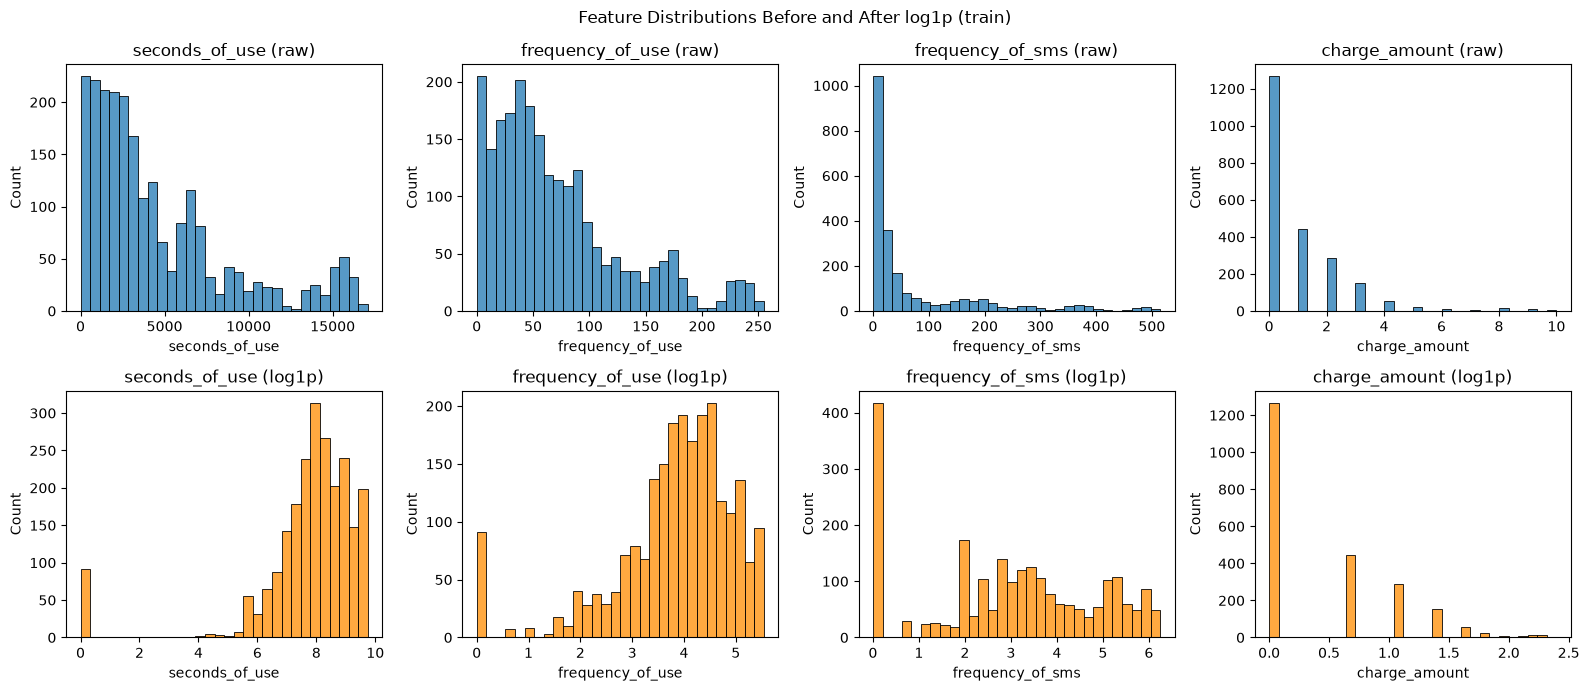

In [26]:
# 5) Distributions before and after log1p (4 features: raw on top, log1p below)
features_to_plot = ['seconds_of_use', 'frequency_of_use', 'frequency_of_sms', 'charge_amount']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, col in enumerate(features_to_plot):
    sns.histplot(X_train_clean[col], bins=30, ax=axes[0, i])
    axes[0, i].set_title(f'{col} (raw)')
    sns.histplot(np.log1p(X_train_clean[col]), bins=30, ax=axes[1, i], color='darkorange')
    axes[1, i].set_title(f'{col} (log1p)')
plt.suptitle('Feature Distributions Before and After log1p (train)')
plt.tight_layout()
plt.show()

**Evaluation:** AP from 0.753 to 0.762, a **small gain** (+0.009). Against the fold-to-fold std (~0.02) this is within noise,
but in the paired comparison (section 10) log1p is better than the baseline on 4 of 5 folds, so the gain is small but fairly consistent.
log1p is kept because it is cheap and matches the data: before the transform the counts have a long right tail (skew 1.0-2.6),
and a few heavy users dominate the linear weights.

The histograms also show the limits of log1p:
- For `seconds_of_use` and `frequency_of_use` it over-corrects: the long right tail becomes a left tail.
- 91 training clients have zero usage: 0 calls, 0 seconds and 0 called numbers at the same time, and they churn at 54% vs 14% for the rest.
  log1p maps them to 0, while every other client starts at 0.7 (calls) and 2.2 (seconds), so they stay a separate spike at the left edge of three features.
  A linear model can only treat this group through the low end of these features. An explicit zero-usage flag (`is_inactive_usage`) is a candidate extra feature for Week 3; it is not part of the Week 1 proposal, so it would be reported as an addition.
- `frequency_of_sms` also keeps a spike at 0 (18% of clients send no SMS), and `charge_amount` stays discrete: log1p only changes the spacing between its levels.
- Sensitivity check on `charge_amount`: leaving it without log1p gives AP 0.765 vs 0.762 with it (paired +0.0026, better in 5/5 folds). The effect is small and exists only for the linear model: tree models in Week 3 do not change under a monotone transform. We keep log1p so that all count-like columns share one transform.

**Encoding:** all features are already numeric: binary (`complains`, `tariff_plan`, `status`) and ordinal
(`age_group` 1-5, `charge_amount` 0-10), so there is no one-hot encoding (it would only add sparse columns). `tariff_plan` and `status` are coded 1/2 in the data; the final pipeline maps them to 0/1 with an OrdinalEncoder, which also turns unseen codes in new data into missing values handled by the imputer.
ColumnTransformer is used in the final Pipeline to route each feature type: log1p for the count features, OrdinalEncoder for the 1/2-coded flags, passthrough for the other numeric features, and drop for the two features removed in section 6.

In [27]:
# 6) Scaling: StandardScaler vs MinMaxScaler vs no scaling (ratios + log1p, LR)
for name, scaler in [('StandardScaler', StandardScaler()), ('MinMaxScaler', MinMaxScaler()), ('no scaling', 'passthrough')]:
    scaling_pipe = Pipeline([
        ('ratios', FunctionTransformer(add_ratios)),
        ('log', FunctionTransformer(log_counts)),
        ('scale', scaler),
        ('model', LogisticRegression(max_iter=1000)),
    ])
    scores = cross_val_score(scaling_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)
    print(f"{name}: mean = {scores.mean():.4f}, std = {scores.std():.4f}")

StandardScaler: mean = 0.7624, std = 0.0224
MinMaxScaler: mean = 0.7564, std = 0.0253
no scaling: mean = 0.7594, std = 0.0213


**Scaling:** all features are scaled for Logistic Regression, including the 0/1 flags, because the L2 penalty treats every coefficient the same way,
so the features must be on a comparable scale. Tree models in Week 3 are not scaled: their splits do not depend on the scale of a feature.

StandardScaler and MinMaxScaler are not interchangeable. MinMaxScaler maps each feature to [0, 1] using only its minimum and maximum,
so a few extreme clients (for example the longest callers) squeeze everyone else into a narrow range.
StandardScaler uses the mean and the standard deviation, which are less sensitive to single extreme values than the min-max range.
CV confirms the choice: StandardScaler 0.762, no scaling 0.759, MinMaxScaler 0.756.
The differences are small (within noise), but MinMaxScaler is the weakest, so StandardScaler is kept.

---
<h2 style="text-align:center; color:blue;">Part 4: Feature Selection</h2>

---

## 9. Feature selection

In [28]:
# 1) RFECV: removes the weakest feature one at a time while the CV AP does not drop
rfecv_pipe = Pipeline([
    ('ratios', FunctionTransformer(add_ratios)),
    ('log', FunctionTransformer(log_counts)),
    ('scale', StandardScaler()),
    ('select', RFECV(LogisticRegression(max_iter=1000), cv=cv, scoring='average_precision')),
    ('model', LogisticRegression(max_iter=1000)),
])

rfecv_cv = cross_val_score(rfecv_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)

# fit on the full train split to see which features are kept
rfecv_pipe.fit(X_train_clean, y_train)
rfecv_features = list(rfecv_pipe.named_steps['select'].get_feature_names_out())

results.append(('+ RFECV', len(rfecv_features), rfecv_cv))
print(f"RFECV: {len(rfecv_features)} features, mean = {rfecv_cv.mean():.4f}, std = {rfecv_cv.std():.4f}")

RFECV: 13 features, mean = 0.7612, std = 0.0238


In [29]:
# 2) Choice of C for L1: the smaller C, the stronger the penalty and the more features are zeroed
for C in [0.01, 0.05, 0.1, 0.5, 1]:
    c_pipe = Pipeline([
        ('ratios', FunctionTransformer(add_ratios)),
        ('log', FunctionTransformer(log_counts)),
        ('scale', StandardScaler()),
        ('select', SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', C=C))),
        ('model', LogisticRegression(max_iter=1000)),
    ])
    c_scores = cross_val_score(c_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)
    c_pipe.fit(X_train_clean, y_train)
    n_kept = len(c_pipe.named_steps['select'].get_feature_names_out())
    print(f"C = {C}: {n_kept} features, mean = {c_scores.mean():.4f}, std = {c_scores.std():.4f}")

C = 0.01: 4 features, mean = 0.7412, std = 0.0386
C = 0.05: 10 features, mean = 0.7552, std = 0.0227
C = 0.1: 12 features, mean = 0.7598, std = 0.0243
C = 0.5: 13 features, mean = 0.7622, std = 0.0238
C = 1: 13 features, mean = 0.7620, std = 0.0234


**C choice:** C = 0.5 and C = 1 keep all 13 features, so they select nothing. C = 0.05 and C = 0.01 remove more features, but AP starts to drop (0.755 and 0.741).
C = 0.1 is the strongest penalty that keeps AP at the level of the full feature set (0.760 vs 0.762), so it is used below.

In [30]:
# 3) L1 regularisation: zeroes the weights of useless features and keeps the rest
l1_pipe = Pipeline([
    ('ratios', FunctionTransformer(add_ratios)),
    ('log', FunctionTransformer(log_counts)),
    ('scale', StandardScaler()),
    ('select', SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', C=0.1))),
    ('model', LogisticRegression(max_iter=1000)),
])

l1_cv = cross_val_score(l1_pipe, X_train_clean, y_train, scoring='average_precision', cv=cv)

l1_pipe.fit(X_train_clean, y_train)
l1_features = list(l1_pipe.named_steps['select'].get_feature_names_out())

# sanity check: with a real L1 penalty some coefficients are exactly zero (an L2 penalty would give none)
l1_coef = l1_pipe.named_steps['select'].estimator_.coef_.ravel()
assert (l1_coef == 0).any(), 'L1 penalty is not active - check the scikit-learn version'
print(f"Coefficients that are exactly zero: {int((l1_coef == 0).sum())}")

results.append(('+ L1 LR', len(l1_features), l1_cv))
print(f"L1: {len(l1_features)} features, mean = {l1_cv.mean():.4f}, std = {l1_cv.std():.4f}")

Coefficients that are exactly zero: 2
L1: 12 features, mean = 0.7598, std = 0.0243


In [31]:
# 4) Both methods side by side (with the full feature set as reference)
all_features = list(X_train_clean.columns) + ['avg_call_duration', 'sms_share', 'failure_rate']

selection_results = pd.DataFrame({
    'Method': ['Full set (no selection)', 'RFECV', 'L1 Logistic Regression'],
    'Features': [len(all_features), len(rfecv_features), len(l1_features)],
    'AP mean': [round(log_cv.mean(), 3), round(rfecv_cv.mean(), 3), round(l1_cv.mean(), 3)],
    'AP std': [round(log_cv.std(), 3), round(rfecv_cv.std(), 3), round(l1_cv.std(), 3)],
    'Selected': [all_features, rfecv_features, l1_features],
    'Removed': [[], [f for f in all_features if f not in rfecv_features],
                [f for f in all_features if f not in l1_features]],
})

pd.set_option('display.max_colwidth', None)
selection_results

,Method,Features,AP mean,AP std,Selected,Removed
0,Full set (no selection),14,0.762,0.022,"[call_failure, complains, subscription_length, charge_amount, seconds_of_use, frequency_of_use, frequency_of_sms, distinct_called_numbers, age_group, tariff_plan, status, avg_call_duration, sms_share, failure_rate]",[]
1,RFECV,13,0.761,0.024,"[call_failure, complains, subscription_length, charge_amount, seconds_of_use, frequency_of_use, frequency_of_sms, distinct_called_numbers, age_group, tariff_plan, status, avg_call_duration, failure_rate]",[sms_share]
2,L1 Logistic Regression,12,0.760,0.024,"[call_failure, complains, subscription_length, charge_amount, frequency_of_use, frequency_of_sms, age_group, tariff_plan, status, avg_call_duration, sms_share, failure_rate]","[seconds_of_use, distinct_called_numbers]"


**Decision:** both methods match the full set (0.762): RFECV 0.761 with 13 features, L1 0.760 with 12. The differences are well within CV noise, so we pick **L1 (12 features)**, the simpler model at the same score. It removes `seconds_of_use` (its information is in `avg_call_duration`) and `distinct_called_numbers` (r = 0.73 with `frequency_of_use`). The two methods disagree on what is redundant (RFECV drops only `sms_share`), which is another sign that these features carry overlapping information.

**Note for Week 3:** selection is done on set A, which still contains `complains` and `status`. Sets B and C drop these flags, so feature selection is repeated for them in Week 3.

---

## 10. Results log and dimensionality reduction

In [32]:
# 1) Results log + paired comparison with the baseline on the same 5 folds
rows = []
for step, n_features, scores in results:
    diff = scores - baseline_cv
    rows.append({
        'Step': step,
        'Features': n_features,
        'AP mean': scores.mean(),
        'AP std': scores.std(),
        'Mean diff vs baseline': diff.mean(),
        'Diff std': diff.std(),
        'Folds better than baseline': (diff > 0).sum(),
    })

pd.DataFrame(rows).round(3)

,Step,Features,AP mean,AP std,Mean diff vs baseline,Diff std,Folds better than baseline
0,baseline,13,0.754,0.021,0.000,0.000,0
1,drop age,12,0.754,0.020,0.000,0.001,3
2,drop seconds_of_use,12,0.750,0.020,-0.004,0.001,0
3,drop frequency_of_use,12,0.730,0.029,-0.024,0.010,0
4,drop customer_value,12,0.754,0.020,0.000,0.001,3
5,drop frequency_of_sms,12,0.755,0.018,0.001,0.004,2
6,drop age + customer_value,11,0.754,0.021,0.000,0.001,3
7,+ 3 ratios,14,0.753,0.019,-0.000,0.004,2
8,+ avg_call_duration only,12,0.754,0.021,-0.000,0.001,1
9,+ sms_share only,12,0.753,0.019,-0.001,0.002,2


**Paired comparison:** every step uses the same 5 folds, so each step can be compared with the baseline fold by fold.
This removes the fold-to-fold noise (std ~0.02) that all steps share.
- Dropping `frequency_of_use` is the only clearly worse step: lower than the baseline on all 5 folds (mean -0.024).
- Dropping `age`, `customer_value` or `frequency_of_sms`, and adding the ratios (together or one at a time), change AP by at most 0.002 on average, so they have no effect.
- Adding log1p is the only step that helps fairly consistently: +0.008 on average and better on 4 of 5 folds, but the gain is small (paired std 0.008).
- Both selected sets keep this gain with fewer features (RFECV +0.007, L1 +0.006).

**Dimensionality reduction: not required.** After selection the model sees 12 features (<= 20), so PCA is not used in the pipeline;
it would also make the features uninterpretable for the app's SHAP explanations.
For completeness, a 2D t-SNE view of the selected features is shown below, fitted on the training data only.

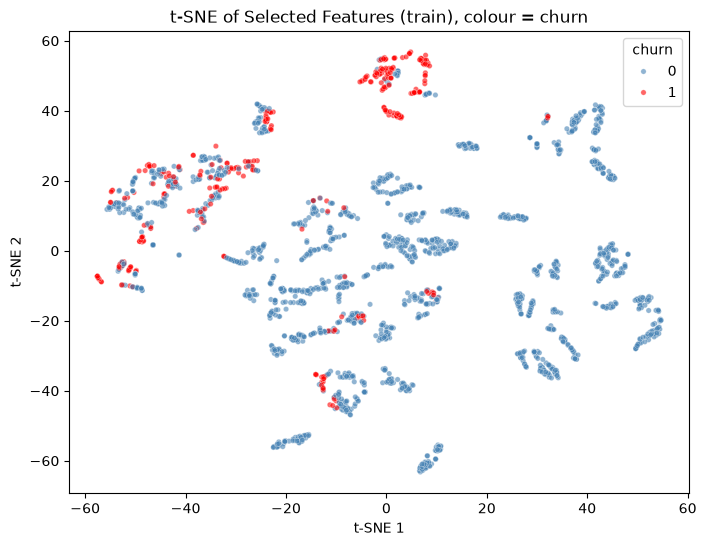

In [33]:
# 2) t-SNE on the selected features (train only), colour = churn
X_train_selected = l1_pipe[:-1].transform(X_train_clean)
X_train_2d = np.asarray(TSNE(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_selected))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_train_2d[:, 0], y=X_train_2d[:, 1], hue=y_train.values, palette={0: 'steelblue', 1: 'red'}, s=15, alpha=0.6)
plt.title('t-SNE of Selected Features (train), colour = churn')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='churn')
plt.show()

**Interpretation:** in the t-SNE plot the training clients form many small, tight clusters. This comes from the discrete features
(`complains`, `status`, `tariff_plan`, `age_group`, `charge_amount`): clients with the same combination of these values land close together.
Churners (red) are not spread evenly. Most of them sit in a few compact clusters that are almost pure churn,
so a good part of the churners is separable. Other churners are mixed into clusters that are mostly non-churn:
these are the hard cases whose features look like those of staying clients.
t-SNE only preserves local structure, so the distances between clusters should not be interpreted.

**Final feature set:** 12 features - `call_failure`, `complains`, `subscription_length`, `charge_amount`, `frequency_of_use`, `frequency_of_sms`, `age_group`, `tariff_plan`, `status`, `avg_call_duration`, `sms_share`, `failure_rate`. Original dataset: 13 predictors.

---
<h2 style="text-align:center; color:blue;">Part 5: Final Pipeline</h2>

---

## 11. Final Pipeline

All decisions above in one object: ratios, ColumnTransformer (log1p for count features, OrdinalEncoder for the 1/2-coded flags, passthrough for the other numeric features, drop for removed features), imputer, scaler, L1 feature selector and a placeholder logistic regression.
The input is the raw 13-feature `X_train`.

In [34]:
# Final pipeline (fitted on X_train in the next cell; X_test is only used to confirm the shapes)
final_pipeline = Pipeline([
    ('ratios', FunctionTransformer(add_ratios)),  # section 7: ratios from the raw values
    ('prep', ColumnTransformer([
        ('log_counts', FunctionTransformer(np.log1p, feature_names_out='one-to-one'),
         ['call_failure', 'seconds_of_use', 'frequency_of_use', 'frequency_of_sms',
          'distinct_called_numbers', 'charge_amount']),                          # section 8: count features
        ('encode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan),
         ['tariff_plan', 'status']),                                              # coded 1/2 in the data -> 0/1
        ('binary', 'passthrough', ['complains']),                                 # already 0/1
        ('numeric', 'passthrough', ['subscription_length', 'age_group',
                                    'avg_call_duration', 'sms_share', 'failure_rate']),
        ('removed', 'drop', ['age', 'customer_value']),                         # section 6
    ], verbose_feature_names_out=False)),
    ('impute', SimpleImputer(strategy='median')),  # no missing values in train; safety net for new data (CSV upload in the app)
    ('scale', StandardScaler()),
    ('select', SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', C=0.1))),  # section 9, L1
    ('model', LogisticRegression(max_iter=1000)),  # placeholder, replaced by the tuned models in Week 3
])

# Check: the assembled pipeline reproduces the CV score of the L1 pipeline from section 9 (input is the raw 13-column X_train)
final_cv = cross_val_score(final_pipeline, X_train, y_train, scoring='average_precision', cv=cv)
print(f"final pipeline: mean = {final_cv.mean():.4f}, std = {final_cv.std():.4f}  |  section 9 L1 pipeline: mean = {l1_cv.mean():.4f}, std = {l1_cv.std():.4f}")

final pipeline: mean = 0.7598, std = 0.0243  |  section 9 L1 pipeline: mean = 0.7598, std = 0.0243


In [35]:
final_pipeline.fit(X_train, y_train)

print(f"X_train after preprocessing: {final_pipeline[:-1].transform(X_train).shape}")
print(f"X_test after preprocessing: {final_pipeline[:-1].transform(X_test).shape}")
print(f"Predictions on X_test: {final_pipeline.predict(X_test).shape}")
print(f"Selected features: {list(final_pipeline.named_steps['select'].get_feature_names_out())}")
print(f"Original dataset: {X_train.shape[1]} predictors -> model sees {final_pipeline[:-1].transform(X_train).shape[1]}")
final_pipeline

X_train after preprocessing: (2280, 12)
X_test after preprocessing: (570, 12)
Predictions on X_test: (570,)
Selected features: ['call_failure', 'frequency_of_use', 'frequency_of_sms', 'charge_amount', 'tariff_plan', 'status', 'complains', 'subscription_length', 'age_group', 'avg_call_duration', 'sms_share', 'failure_rate']
Original dataset: 13 predictors -> model sees 12


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ratios', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['call_failure','complains','subscription_length',...,'status','age', 'customer_value']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...t 0x17fc70b40>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
